In [0]:
# Load CSV (works in Databricks Volume and locally after cloning from GitHub)
possible_paths = [
    "/Volumes/workspace/default/bank_project/project 2 classification (2).csv",
    "data/bank.csv",
    "bank.csv",
    "project 2 classification (2).csv",
]
csv_path = next((p for p in possible_paths if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place 'bank.csv' in the project root or inside a 'data/' folder."
    )

bank = pd.read_csv(csv_path)
print(f"Loaded dataset from: {csv_path}")
print(bank.head())

   age        job  marital  ... euribor3m nr.employed SUBSCRIBED
0   56  housemaid  married  ...     4.857      5191.0         no
1   57   services  married  ...     4.857      5191.0         no
2   37   services  married  ...     4.857      5191.0         no
3   40     admin.  married  ...     4.857      5191.0         no
4   56   services  married  ...     4.857      5191.0         no

[5 rows x 22 columns]


Basic checks of the dataframe

In [0]:
#dimension of the bank dataframe
print("\nDataframe dimensions:",bank.shape)
#column names
print("\ncolumn names",bank.columns)
#bank data information
bank.info()
#bank data description
print("--Data description--")
print(bank.describe())
#types in the bank dataset
print("Types in the bank dataset:",bank.dtypes)
#unique types in the dataset
print("Unique types in the bank dataset:",bank.dtypes.unique())
#number of unique values for each column
print('Unique values for each column:',bank.nunique())
#number of missing values for each column
print('\n number of missing values:',bank.isnull().sum())
#checking the proportion of the response/target variable
print('\n--Proportion of the response variable--')
target=bank['SUBSCRIBED']
#count the number of observations for each class
print("The number of observations for each class is:\n",target.value_counts())
#count the proportions of classes of the target variable
print(target.value_counts(normalize=True))


Dataframe dimensions: (39883, 22)

column names Index(['age', 'job', 'marital', 'otherproduct', 'education', 'default',
       'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration',
       'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed',
       'SUBSCRIBED'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39883 entries, 0 to 39882
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             39883 non-null  int64  
 1   job             39883 non-null  object 
 2   marital         39883 non-null  object 
 3   otherproduct    39883 non-null  object 
 4   education       39883 non-null  object 
 5   default         39883 non-null  object 
 6   housing         39883 non-null  object 
 7   loan            39883 non-null  object 
 8   contact         39883 non-null  object 
 9   month          

--pdays_was_contacted 5 first observations--
0    0
1    0
2    0
3    0
4    0
Name: pdays_was_contacted, dtype: int64
pdays_was_contacted distribution:
pdays_was_contacted
0    38831
1     1052
Name: count, dtype: int64

pdays_was_contacted proportions:
pdays_was_contacted
0    0.973623
1    0.026377
Name: proportion, dtype: float64


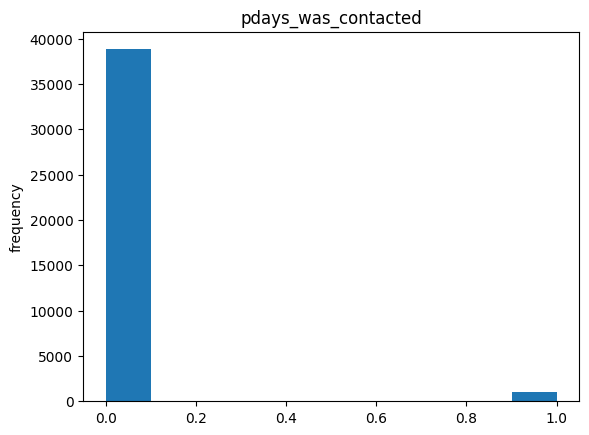

In [0]:
#pdays contain 999 special code number, so we must change the variable
#999 means the client was never previously contacted
#We create a binary variable: 1 = was contacted before, 0 = was not contacted
bank['pdays_was_contacted'] = (bank['pdays'] != 999).astype(int)

#see the first 5 ovservation of the new created variable
print('--pdays_was_contacted 5 first observations--')
print(bank['pdays_was_contacted'].head(5))

#Check the distribution of the new variable
print('pdays_was_contacted distribution:')
print(bank['pdays_was_contacted'].value_counts())
print('\npdays_was_contacted proportions:')
print(bank['pdays_was_contacted'].value_counts(normalize=True))

#histogram for pdays_was_contacted
plt.hist(bank['pdays_was_contacted'])
plt.title('pdays_was_contacted')
plt.ylabel('frequency')
plt.show()

#remove original pdyas variable
bank=bank.drop(columns=['pdays'])

Visual inspection of the data

job
admin.           10020
blue-collar       9174
technician        6537
services          3894
management        2845
retired           1543
entrepreneur      1437
self-employed     1390
housemaid         1029
unemployed         960
student            737
unknown            317
Name: count, dtype: int64
marital
married     24320
single      11015
divorced     4469
unknown        79
Name: count, dtype: int64
education
university.degree      11667
high.school             9218
basic.9y                5971
professional.course     5049
basic.4y                4047
basic.6y                2270
unknown                 1643
illiterate                18
Name: count, dtype: int64
default
no         31309
unknown     8571
yes            3
Name: count, dtype: int64
housing
yes        20869
no         18059
unknown      955
Name: count, dtype: int64
loan
no         32868
yes         6060
unknown      955
Name: count, dtype: int64
contact
cellular     25089
telephone    14794
Name: count, dtype: in

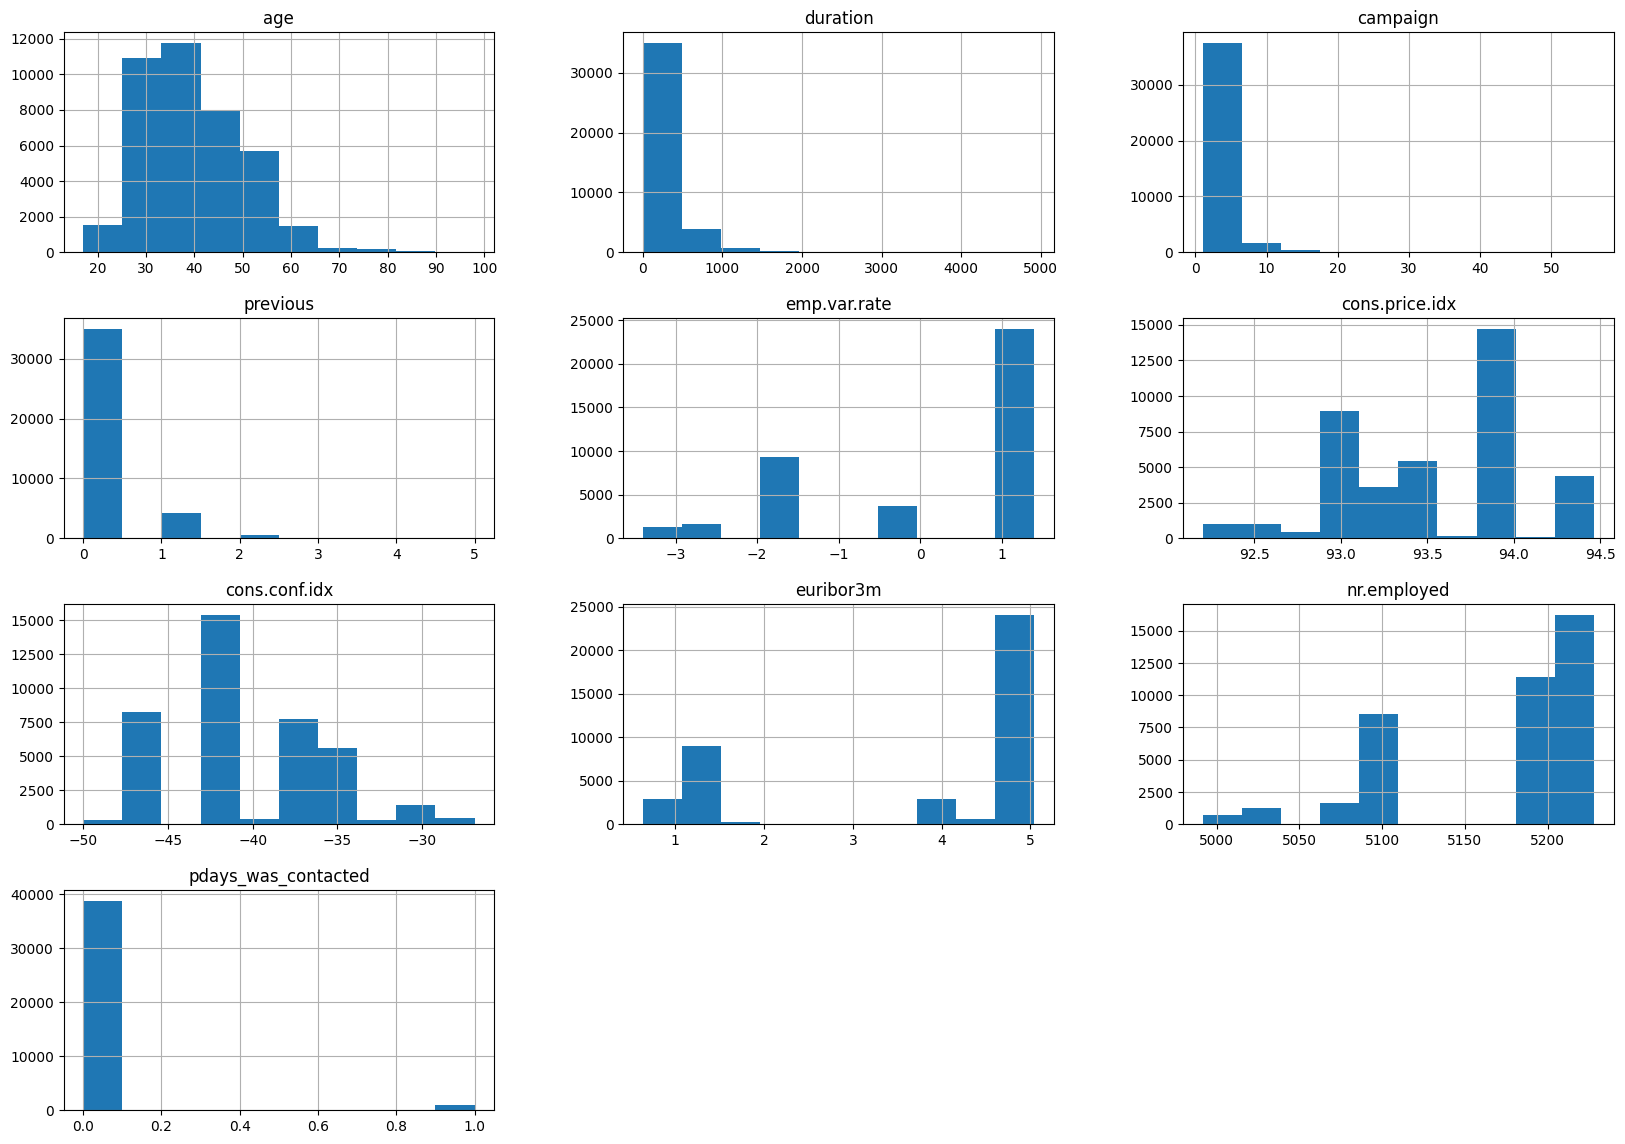

In [0]:
#histograms for the numeric variables
bank.hist(figsize=(20,14))

#a look at the distribution of values for the categorical variables
print(bank['job'].value_counts())
print(bank['marital'].value_counts())
print(bank['education'].value_counts())
print(bank['default'].value_counts())
print(bank['housing'].value_counts())
print(bank['loan'].value_counts())
print(bank['contact'].value_counts())
print(bank['month'].value_counts())
print(bank['day_of_week'].value_counts())
print(bank['poutcome'].value_counts())
print(bank['otherproduct'].value_counts())

#Now lets look at the relationshop between the categorical variables and the target(categorical vs categorical)

print(pd.crosstab(index=bank['job'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['marital'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['education'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['default'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['housing'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['loan'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['contact'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['month'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['day_of_week'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['poutcome'],columns=bank['SUBSCRIBED']))
print(pd.crosstab(index=bank['otherproduct'],columns=bank['SUBSCRIBED']))

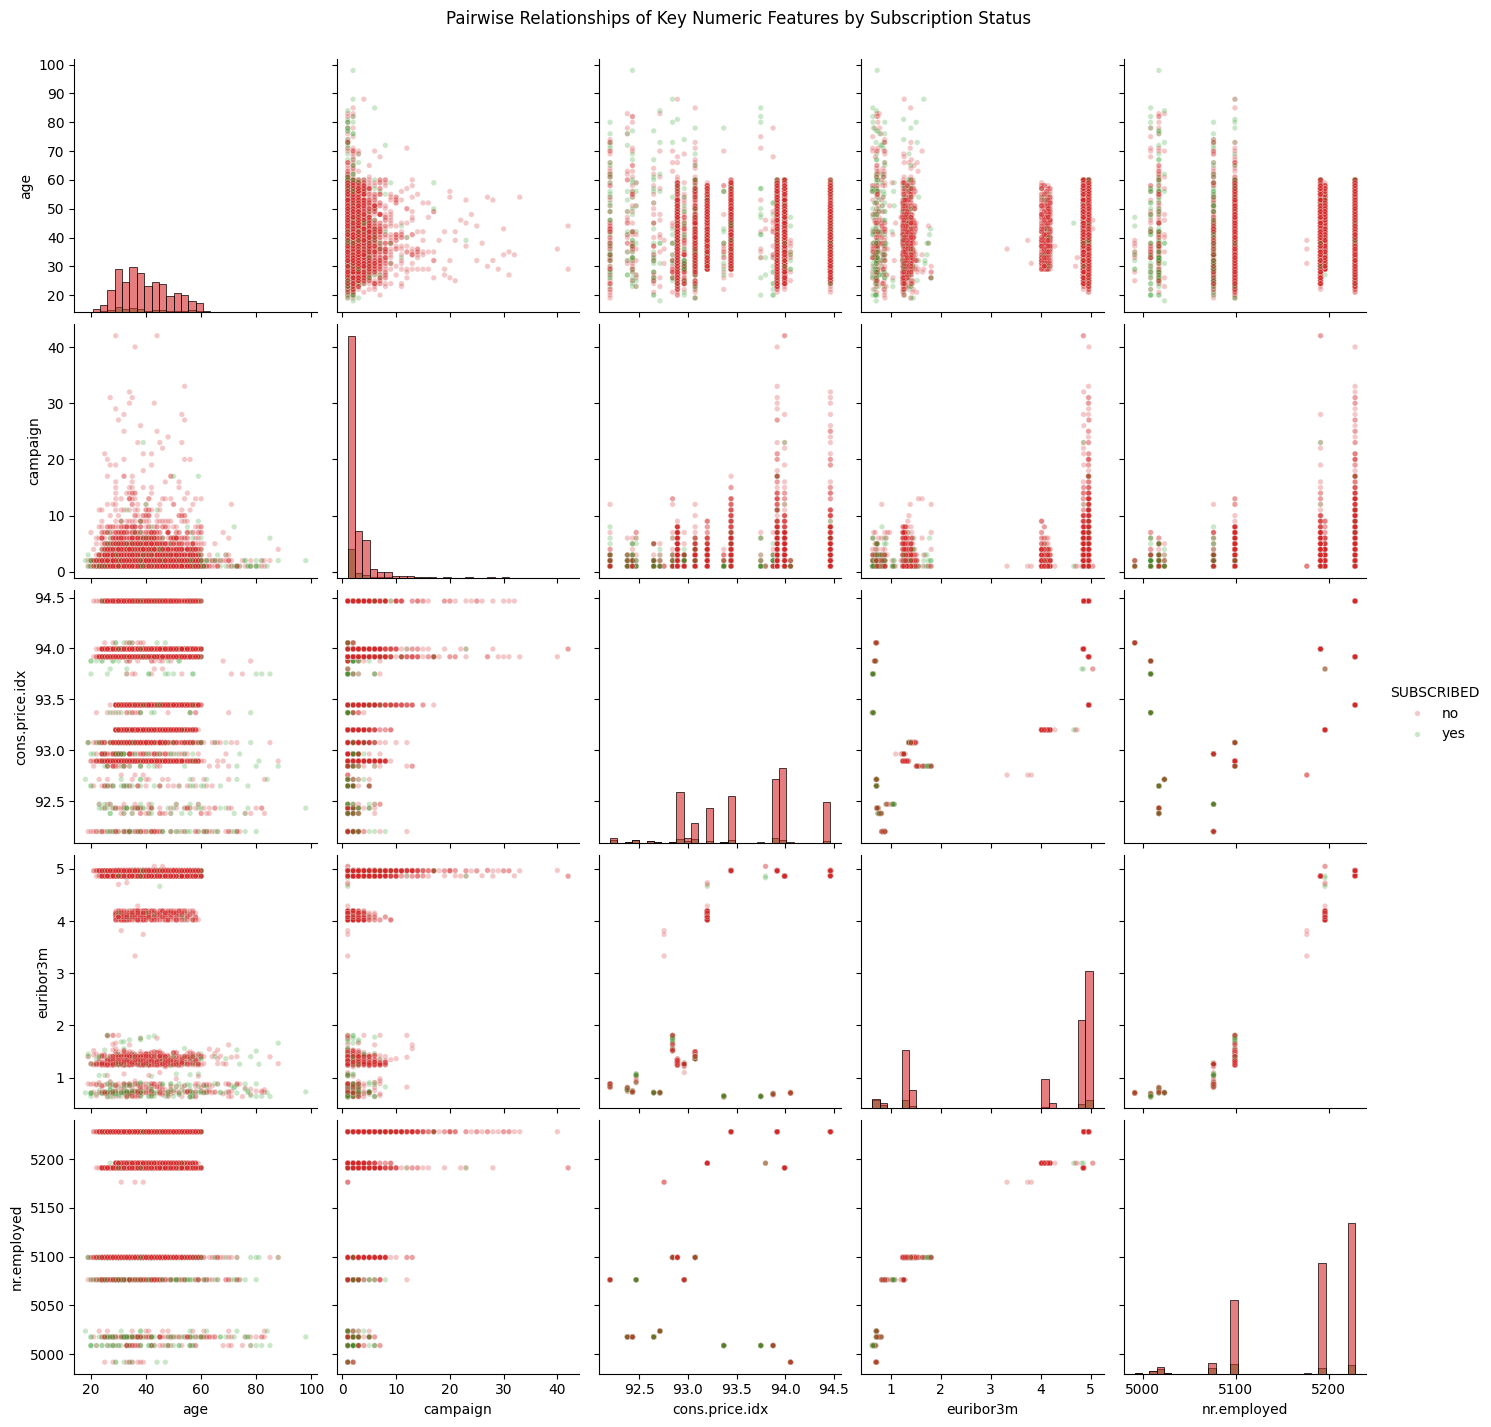

In [0]:
#Create a pairplot and show how each variable differs according to our response variable Subscribed

import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define sample size and key numeric features to inspect
n_samples_to_plot = 5000
numeric_columns = ['age', 'campaign', 'cons.price.idx', 'euribor3m', 'nr.employed']

# 2. Random sample to avoid bias from row ordering (e.g., chronological sorting by month)
bank_sample = bank.sample(n=min(n_samples_to_plot, len(bank)), random_state=42)

# 3. Generate the pairplot
sns.pairplot(
    data=bank_sample,
    vars=numeric_columns,
    hue='SUBSCRIBED',
    plot_kws={'alpha': 0.25, 's': 15},   # Transparency helps reveal dense subscription clusters
    diag_kind='hist',
    diag_kws={'bins': 30, 'alpha': 0.6},
    height=2.8,
    palette={'yes': '#2ca02c', 'no': '#d62728'})

plt.suptitle("Pairwise Relationships of Key Numeric Features by Subscription Status", y=1.02)
plt.show()

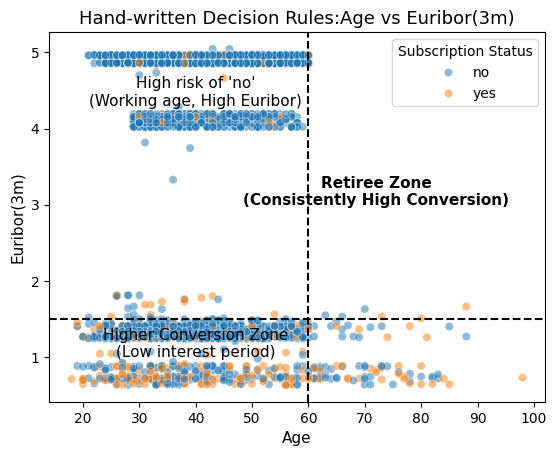

In [0]:
import matplotlib.pyplot as plt
bank_sample=bank.sample(n=5000,random_state=42)
ax=sns.scatterplot(x="age",
                   y="euribor3m",
                   hue="SUBSCRIBED",
                   data=bank_sample,
                   alpha=0.5
                   )
#decision boundary thresholds
age_threshold=60
euribor_threshold=1.5
#decision boundary lines
plt.axvline(x=age_threshold,color="black",linestyle="--")
plt.axhline(y=euribor_threshold,xmin=0,xmax=1,color="black",linestyle="--")           
#region annonations
plt.annotate("High risk of 'no'\n(Working age, High Euribor)",xy=(40,4.3),fontsize=11,ha="center")
plt.annotate("Higher Conversion Zone\n(Low interest period)",xy=(40,1.0),fontsize=11,ha="center")
plt.annotate("Retiree Zone\n(Consistently High Conversion)",xy=(72,3.0),fontsize=11,weight="bold",ha="center")
plt.title("Hand-written Decision Rules:Age vs Euribor(3m)",fontsize=13)
plt.xlabel("Age",fontsize=11)
plt.ylabel("Euribor(3m)",fontsize=11)
plt.legend(title="Subscription Status",loc="upper right")
plt.show()

Data Cleaning

In [0]:
#convert otherproduct strings
bank['otherproduct'] = bank['otherproduct'].str.lower()
#see the first 5 observations from the job variable
bank['job'].head(5)
#drop duration to prevent data-leakage
bank=bank.drop(columns=['duration'])
#convert object variables into categoricals
bank["job"]=bank["job"].astype("category")
bank["marital"]=bank["marital"].astype("category")
bank["education"]=bank["education"].astype("category")
bank["default"]=bank["default"].astype("category")
bank["housing"]=bank["housing"].astype("category")
bank["loan"]=bank["loan"].astype("category")
bank["contact"]=bank["contact"].astype("category")
bank["month"]=bank["month"].astype("category")
bank["day_of_week"]=bank["day_of_week"].astype("category")
bank["poutcome"]=bank["poutcome"].astype("category")
bank["otherproduct"]=bank["otherproduct"].astype("category")
bank["SUBSCRIBED"]=bank["SUBSCRIBED"].astype("category")
#print the 5 first observations from the SUBSCRIBED response variable
print(bank["SUBSCRIBED"].head(5))

#remove duplicates
bank=bank.drop_duplicates() # or we can use this: bank.drop_duplicates(inplace=True)
#check the number of rows and columns
print("\nBank Shape")
print(bank.shape)
#check the number of missing values
print("\nMissing values")
print(bank.isnull().sum())
#check the number of unique values for each column
print("Number of unique values for each column:",bank.nunique())
print("bank data types:\n",bank.dtypes)

0    no
1    no
2    no
3    no
4    no
Name: SUBSCRIBED, dtype: category
Categories (2, object): ['no', 'yes']

Bank Shape
(38912, 21)

Missing values
age                    0
job                    0
marital                0
otherproduct           0
education              0
default                0
housing                0
loan                   0
contact                0
month                  0
day_of_week            0
campaign               0
previous               0
poutcome               0
emp.var.rate           0
cons.price.idx         0
cons.conf.idx          0
euribor3m              0
nr.employed            0
SUBSCRIBED             0
pdays_was_contacted    0
dtype: int64
Number of unique values for each column: age                     78
job                     12
marital                  4
otherproduct             2
education                8
default                  3
housing                  3
loan                     3
contact                  2
month                   10

Exploratory Data Analysis

--Frequency of SUBSCRIBED--
SUBSCRIBED
no     34943
yes     3969
Name: count, dtype: int64
--Proportion of SUBSCRIBED--
SUBSCRIBED
no     0.898001
yes    0.101999
Name: proportion, dtype: float64


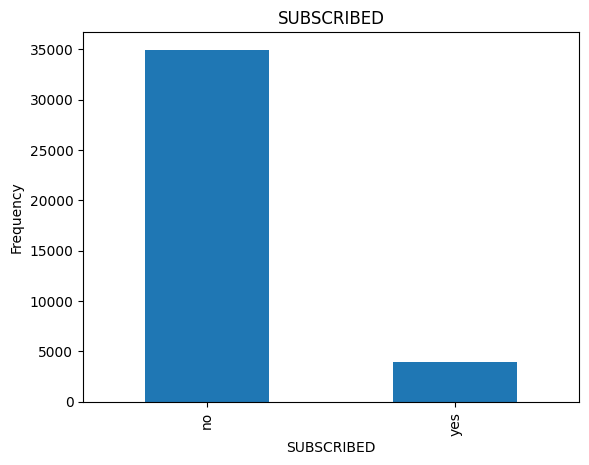

In [0]:
target = bank["SUBSCRIBED"]
#check the frequency of yes and no in the response variable
print("--Frequency of SUBSCRIBED--")
print(target.value_counts())
#the frequency of yes and no in the response variable as proportions
print('--Proportion of SUBSCRIBED--')
print(target.value_counts(normalize=True))
#bank['SUBSCRIBED'].value_counts().plot.bar()
target.value_counts().plot.bar(title="SUBSCRIBED")
plt.xlabel("SUBSCRIBED")
plt.ylabel("Frequency")
plt.show()

In [0]:
#group the variables for the analysis into categorical and numeric
#SUBSCRIBED is the response variable so we will not include it from the numeric list for the correlation plot
numeric_vars = ["age", "campaign", "pdays_was_contacted", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print(numeric_vars)
categorical_vars = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome", "otherproduct", "SUBSCRIBED"]
print(categorical_vars)
#Correlation matrix
corr_matrix=bank[numeric_vars].corr(method='pearson')
corr_matrix

['age', 'campaign', 'pdays_was_contacted', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'otherproduct', 'SUBSCRIBED']


,age,campaign,pdays_was_contacted,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.000000,0.001906,0.030710,0.014927,0.006541,-0.004414,0.139360,0.021392,-0.004631
campaign,0.001906,1.000000,-0.048851,-0.081429,0.150691,0.142851,-0.017210,0.132771,0.145718
pdays_was_contacted,0.030710,-0.048851,1.000000,0.526604,-0.266691,-0.180775,0.133043,-0.263333,-0.310467
previous,0.014927,-0.081429,0.526604,1.000000,-0.445308,-0.349239,-0.035888,-0.450806,-0.463940
emp.var.rate,0.006541,0.150691,-0.266691,-0.445308,1.000000,0.848345,0.192248,0.978055,0.953925
cons.price.idx,-0.004414,0.142851,-0.180775,-0.349239,0.848345,1.000000,0.084338,0.805169,0.734006
cons.conf.idx,0.139360,-0.017210,0.133043,-0.035888,0.192248,0.084338,1.000000,0.277636,0.081187
euribor3m,0.021392,0.132771,-0.263333,-0.450806,0.978055,0.805169,0.277636,1.000000,0.960682
nr.employed,-0.004631,0.145718,-0.310467,-0.463940,0.953925,0.734006,0.081187,0.960682,1.000000


Correlation plot

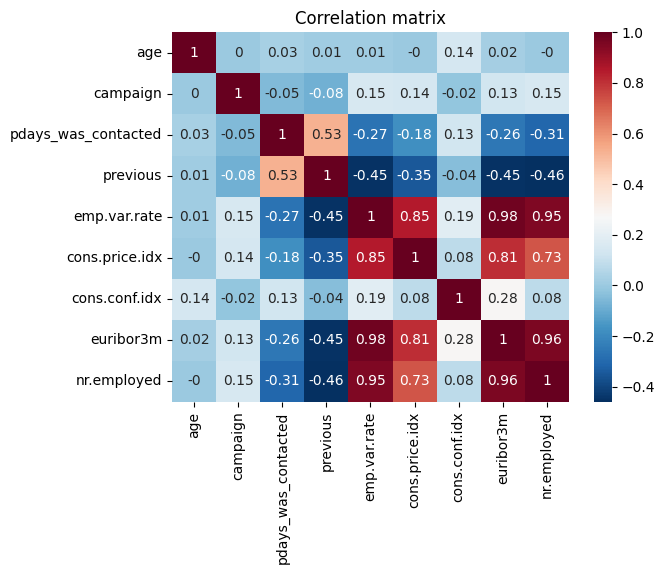

emp.var.rate euribor3m 0.98
emp.var.rate nr.employed 0.95
euribor3m nr.employed 0.96


In [0]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
#Compute correlation matrix
corr_matrix = bank[numeric_vars].corr(method='pearson')
#Plot correlation heatmap
sns.heatmap(corr_matrix.round(2), cmap="RdBu_r", annot=True)#, vmin=-1, vmax=1)
plt.title("Correlation matrix")
#Display heatmap
plt.show()

#threshold for the correllation score
threshold = 0.85
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        correlation = corr_matrix.iloc[i, j]
        if abs(correlation) > threshold:
            print(corr_matrix.columns[i],corr_matrix.columns[j],
                  round(correlation, 2))

In [0]:
#drop highly correlated variables with corr>0.85
bank=bank.drop(columns=['euribor3m','nr.employed'], errors='ignore')
#update the numeric list
numeric = ["age", "campaign", "pdays_was_contacted", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx"]
print('\nupdated shape:', bank.shape)
print('\nupdated numeric list:', numeric)





updated shape: (38912, 19)

updated numeric list: ['age', 'campaign', 'pdays_was_contacted', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx']


In [0]:
print("--- Outliers Detected (IQR Method) ---")

#Check for outliers in numeric variables
for variable in numeric:
    Q1 = bank[variable].quantile(0.25)
    Q3 = bank[variable].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = bank[
        (bank[variable] < lower) |
        (bank[variable] > upper)
    ]
    
    # Using an f-string for a cleaner printout
    print(f"{variable}: {len(outliers)} outliers ({len(outliers) / len(bank) * 100:.2f}%)")

--- Outliers Detected (IQR Method) ---
age: 359 outliers (0.92%)
campaign: 2384 outliers (6.13%)
pdays_was_contacted: 1050 outliers (2.70%)
previous: 4816 outliers (12.38%)
emp.var.rate: 0 outliers (0.00%)
cons.price.idx: 0 outliers (0.00%)
cons.conf.idx: 442 outliers (1.14%)


Split the data into train, test and validation set

In [0]:
### Split the Data into Train, Test, and Validation Sets
#Note: Following the three-way holdout convention, the train set (60%) is used for 10-fold CV and threshold tuning, the test set (20%) is used to compare and select the best model, and the validation set (20%) remains untouched for final generalization testing.*

#Remove the response variable 'SUBSCRIBED' from the features
#Note: 'euribor3m' and 'nr.employed' were already removed in the correlation step
bank_model= bank.drop(columns=['SUBSCRIBED'])
#checks on the modelling dataset
print("the modelling dataset types are:\n",bank_model.dtypes)
print("the shape of the modelling dataset is:\n",bank_model.shape)
print(bank_model.head())

#Define X (features) and y (response)
#Keep all categories for each categorical variable (drop_first=False)
x=bank_model
target=bank['SUBSCRIBED']
print("the response variable is:\n",target)
print("the shape of the response variable is:\n",target.shape)
y = bank["SUBSCRIBED"].map({"no": 0, "yes": 1}).astype(int)
target=y
#Split into 60% train, 20% test, 20% validation
#First split: 60% train, 40% temp (test+validation)
from sklearn.model_selection import train_test_split
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.40, random_state=27, stratify=y)

#Second split: 50% of temp for test, 50% for validation (20%/20% of total)
x_test, x_valid, y_test, y_valid = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=27, stratify=y_temp
)

print('\nTrain set:', x_train.shape, y_train.shape)
print('Test set:', x_test.shape, y_test.shape)
print('Validation set:', x_valid.shape, y_valid.shape)

#Check the proportions of the response variable in each set
print('\nResponse proportions:')
print('Train:\n', y_train.value_counts(normalize=True))
print('\nTest:\n', y_test.value_counts(normalize=True))
print('\nValidation:\n', y_valid.value_counts(normalize=True))

from sklearn.model_selection import StratifiedKFold

# Shared 10-fold stratified CV splitter (preserves ~90/10 class ratio in every fold)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=27)


the modelling dataset types are:
 age                       int64
job                    category
marital                category
otherproduct           category
education              category
default                category
housing                category
loan                   category
contact                category
month                  category
day_of_week            category
campaign                  int64
previous                  int64
poutcome               category
emp.var.rate            float64
cons.price.idx          float64
cons.conf.idx           float64
pdays_was_contacted       int64
dtype: object
the shape of the modelling dataset is:
 (38912, 18)
   age        job  marital  ... cons.price.idx cons.conf.idx pdays_was_contacted
0   56  housemaid  married  ...         93.994         -36.4                   0
1   57   services  married  ...         93.994         -36.4                   0
2   37   services  married  ...         93.994         -36.4                   0


Dummy Classifier (Baseline model)

In [0]:
# Dummy classifier tells us the minimum score any real model must beat
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# Fit DummyClassifier on the training set
dummy = DummyClassifier(strategy="stratified", random_state=27)
dummy.fit(x_train, y_train)

# Predict on the test set
y_dummy_pred = dummy.predict(x_test)

# Compute test set metrics (matching your KNN evaluation format)
print("Dummy Test Accuracy:", accuracy_score(y_test, y_dummy_pred))
print("Dummy Test Precision:", precision_score(y_test, y_dummy_pred, zero_division=0))
print("Dummy Test Recall:", recall_score(y_test, y_dummy_pred, zero_division=0))
print("Dummy Test F1:", f1_score(y_test, y_dummy_pred, zero_division=0))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_dummy_pred))
print("\nClassification Report:\n", classification_report(y_test, y_dummy_pred, zero_division=0))

Dummy Test Accuracy: 0.8111025443330764
Dummy Test Precision: 0.09857482185273159
Dummy Test Recall: 0.10453400503778337
Dummy Test F1: 0.10146699266503667

Confusion Matrix:
 [[6229  759]
 [ 711   83]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.89      0.89      6988
           1       0.10      0.10      0.10       794

    accuracy                           0.81      7782
   macro avg       0.50      0.50      0.50      7782
weighted avg       0.82      0.81      0.81      7782



K-Nearest-Neighbours

In [0]:
#K-Nearest-Neighbours model
#KNN works only with numerical variables
#Because KNN works with distances we should scale them
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score

# Identify the original continuous columns
num_cols = bank_model.select_dtypes(include=["int64", "float64"]).columns.tolist()

#Scale only continuous columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
    ],
    remainder="drop", #drops all categorical columns automatically
)

knn = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier()),
])

from sklearn.model_selection import cross_validate

cv_results = cross_validate(knn, x_train, y_train, cv=skf, scoring=["accuracy", "precision", "recall", "f1"])

#print the metrics 
print("Average accuracy:\n", cv_results["test_accuracy"].mean())
print("Average precision:\n", cv_results["test_precision"].mean())
print("Average recall:\n", cv_results["test_recall"].mean())
print("Average f1:\n", cv_results["test_f1"].mean())

#Grid search for the best parameters
from sklearn.model_selection import GridSearchCV
param_grid={
    "knn__n_neighbors": (3,5,7,9,11,13,15,17,19,21,23,25,27,29,31,33,35,37,39,41,43,45,47,49,51,53,55,57,59,61,63,65,67,69,71,73,75,77,79,81,83,85,87,89,91,93,95,97,99,101)
}
model_grid_search=GridSearchCV(knn, param_grid, scoring="f1", cv=skf)
model_grid_search.fit(x_train,y_train)
print("The best parameters are:\n",model_grid_search.best_params_)
print("The best score is:\n",model_grid_search.best_score_)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

#Already fitted on x_train[num_cols] with n_neighbors=3
best_knn = model_grid_search.best_estimator_

#Predict on the test set
y_test_pred = best_knn.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Precision:", precision_score(y_test, y_test_pred))
print("Test Recall:", recall_score(y_test, y_test_pred))
print("Test F1:", f1_score(y_test, y_test_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("\nClassification Report:\n", classification_report(y_test, y_test_pred))

Average accuracy:
 0.896860321951452
Average precision:
 0.4879656903016403
Average recall:
 0.22176259625188993
Average f1:
 0.30426895787230607
The best parameters are:
 {'knn__n_neighbors': 3}
The best score is:
 0.3133953798096788
Test Accuracy: 0.8862760215882807
Test Precision: 0.40421052631578946
Test Recall: 0.24181360201511334
Test F1: 0.30260047281323876

Confusion Matrix:
 [[6705  283]
 [ 602  192]]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.96      0.94      6988
           1       0.40      0.24      0.30       794

    accuracy                           0.89      7782
   macro avg       0.66      0.60      0.62      7782
weighted avg       0.87      0.89      0.87      7782



Decision Boundary for KNN (k=3) using 2 continuous variables (2D)

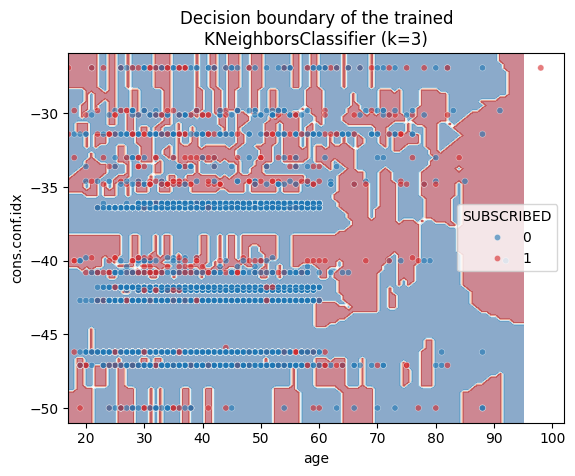

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Select 2 continuous features (analogous to culmen_columns in your notes)
plot_cols = ["age", "cons.conf.idx"]

# 2. Fit the 2D pipeline
knn_2d = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
knn_2d.fit(x_train[plot_cols], y_train)

# 3. Plot the decision boundary and overlay points
DecisionBoundaryDisplay.from_estimator(
    knn_2d,
    x_valid[plot_cols],
    response_method="predict",  # or "predict_proba" for smoother probability shading
    cmap="RdBu_r",
    alpha=0.5,
)

sns.scatterplot(
    x=x_test[plot_cols[0]],
    y=x_test[plot_cols[1]],
    hue=y_test,
    palette={0: "tab:blue", 1: "tab:red"},
    alpha=0.6,
    s=20,
)

plt.title("Decision boundary of the trained\nKNeighborsClassifier (k=3)")
plt.show()

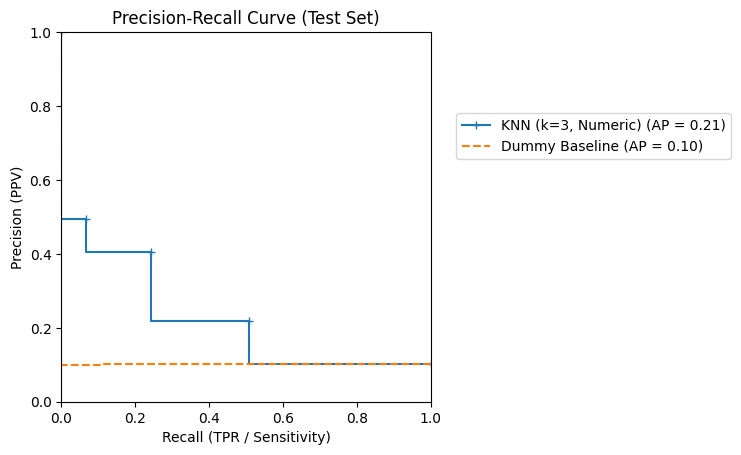

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

# Plot Precision-Recall curve for tuned KNN (k=3)
disp = PrecisionRecallDisplay.from_estimator(
    best_knn,
    x_test,
    y_test,
    pos_label=1,
    name="KNN (k=3, Numeric)",
    marker="+",
)

# Overlay DummyClassifier baseline on the same axes
PrecisionRecallDisplay.from_estimator(
    dummy,
    x_test,
    y_test,
    pos_label=1,
    name="Dummy Baseline",
    color="tab:orange",
    linestyle="--",
    ax=disp.ax_,
)

plt.xlabel("Recall (TPR / Sensitivity)")
plt.ylabel("Precision (PPV)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
disp.ax_.set_title("Precision-Recall Curve (Test Set)")
plt.show()

Logistic Regression

Average accuracy:
 0.9040988533713525
Average precision:
 0.6137708808700746
Average recall:
 0.16001195457262402
Average f1:
 0.25328375943900283
The best parameters are:
 {'logreg__C': 0.5, 'logreg__class_weight': 'balanced'}
The best score is:
 0.3952353358412898
Total features after encoding: 62
Features kept by LASSO: 51
Features dropped by LASSO: 11

Selected features and weights:
                                Feature  Coefficient
4                  num__cons.price.idx     1.297651
45                      cat__month_aug     0.837434
49                      cat__month_mar     0.644138
22                cat__marital_unknown     0.593857
61               cat__poutcome_success     0.536569
15                    cat__job_student     0.429996
52                      cat__month_oct     0.342792
12                    cat__job_retired     0.292638
46                      cat__month_dec     0.200045
33                     cat__default_no     0.141914
6             num__pdays_was_contacte

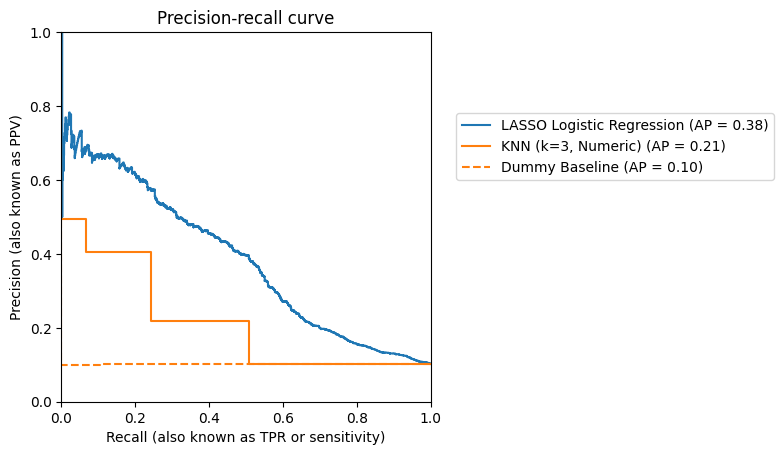

In [0]:
# LASSO Logistic Regression model
# LASSO uses an L1 penalty to shrink weak feature coefficients to exact zero
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns from x_train
num_cols = x_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = x_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Scale numerical columns and one-hot encode categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

# Create the pipeline with L1 (LASSO) regularization
logreg = Pipeline([
    ("preprocessor", preprocessor),
    ("logreg", LogisticRegression(penalty="l1", solver="liblinear", random_state=27)),
])

# Cross-validation on the training set before tuning
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    logreg, x_train, y_train, cv=skf, scoring=["accuracy", "precision", "recall", "f1"]
)

# Print the cross-validation metrics
print("Average accuracy:\n", cv_results["test_accuracy"].mean())
print("Average precision:\n", cv_results["test_precision"].mean())
print("Average recall:\n", cv_results["test_recall"].mean())
print("Average f1:\n", cv_results["test_f1"].mean())

# Grid search for the best parameters
from sklearn.model_selection import GridSearchCV

param_grid = {
    "logreg__C": (0.01, 0.05, 0.1, 0.5, 1, 5, 10),
    "logreg__class_weight": (None, "balanced"),
}

model_grid_search = GridSearchCV(logreg, param_grid, scoring="f1", cv=skf)
model_grid_search.fit(x_train, y_train)

print("The best parameters are:\n", model_grid_search.best_params_)
print("The best score is:\n", model_grid_search.best_score_)

# Check which variables LASSO kept and which ones it dropped (coef == 0)
best_logreg = model_grid_search.best_estimator_

feature_names = best_logreg.named_steps["preprocessor"].get_feature_names_out()
coefficients = best_logreg.named_steps["logreg"].coef_[0]

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
})

kept_features = coef_table[coef_table["Coefficient"] != 0].sort_values(
    by="Coefficient", ascending=False
)
dropped_features = coef_table[coef_table["Coefficient"] == 0]

print("Total features after encoding:", len(coef_table))
print("Features kept by LASSO:", len(kept_features))
print("Features dropped by LASSO:", len(dropped_features))
print("\nSelected features and weights:\n", kept_features)

# Predict on the test set
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

y_test_pred = best_logreg.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Test Recall:", recall_score(y_test, y_test_pred))
print("Test F1:", f1_score(y_test, y_test_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("\nClassification Report:\n", classification_report(y_test, y_test_pred))

# Precision-Recall curve comparing LASSO, KNN, and Dummy on the test set
from sklearn.metrics import PrecisionRecallDisplay

disp = PrecisionRecallDisplay.from_estimator(
    best_logreg, x_test, y_test, pos_label=1, name="LASSO Logistic Regression"
)
PrecisionRecallDisplay.from_estimator(
    best_knn, x_test, y_test, pos_label=1, name="KNN (k=3, Numeric)", ax=disp.ax_
)
PrecisionRecallDisplay.from_estimator(
    dummy,
    x_test,
    y_test,
    pos_label=1,
    name="Dummy Baseline",
    color="tab:orange",
    linestyle="--",
    ax=disp.ax_,
)

plt.xlabel("Recall (also known as TPR or sensitivity)")
plt.ylabel("Precision (also known as PPV)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
disp.ax_.set_title("Precision-recall curve")
plt.show()

Random Forest

In [0]:
#Random Forest builds an ensemble of decision trees and averages their class probabilities
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, RandomizedSearchCV,cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    PrecisionRecallDisplay,
)

num_cols=x_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols=x_train.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

rf = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(oob_score=True, random_state=27, n_jobs=2)),
])

param_distributions={
    "rf__max_features":(2,3,4,5),
    "rf__max_leaf_nodes":(50,100,200,300),
    "rf__class_weight":(None,"balanced")
}

search_cv=RandomizedSearchCV(
    rf,
    param_distributions=param_distributions,
    scoring="f1",
    cv=skf,
    n_iter=10,
    random_state=0,
    n_jobs=2,
)

# Fit the models on the training set
search_cv.fit(x_train, y_train)

# Extract the best Random Forest pipeline
best_rf = search_cv.best_estimator_
print("The best parameters are:\n", search_cv.best_params_)
print("Best 10-fold CV F1 score (train set):\n", round(search_cv.best_score_, 4))
print("Random Forest Out-of-Bag (OOB) Accuracy:\n", round(best_rf.named_steps["rf"].oob_score_, 4))

# Find the F1-optimal probability threshold on training CV predictions (leak-free)
train_probs_rf = cross_val_predict(
    best_rf,
    x_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.90, 0.01)
oof_f1_scores = [f1_score(y_train, (train_probs_rf >= t).astype(int)) for t in thresholds]
best_thresh_rf = thresholds[np.argmax(oof_f1_scores)]

print("Optimal decision threshold (train CV):", round(best_thresh_rf, 2))
print("Train OOF F1 at optimal threshold:    ", round(max(oof_f1_scores), 4))

# Predict and evaluate on the unseen test set using the tuned threshold
test_probs_rf = best_rf.predict_proba(x_test)[:, 1]
y_pred_rf = (test_probs_rf >= best_thresh_rf).astype(int)

print("\n--- Test Set Results (Random Forest + Tuned Threshold) ---")
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Test Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Test Recall:", recall_score(y_test, y_pred_rf))
print("Test F1:", f1_score(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

The best parameters are:
 {'rf__max_leaf_nodes': 200, 'rf__max_features': 4, 'rf__class_weight': 'balanced'}
Best 10-fold CV F1 score (train set):
 0.4179
Random Forest Out-of-Bag (OOB) Accuracy:
 0.8329
Optimal decision threshold (train CV): 0.62
Train OOF F1 at optimal threshold:     0.4582

--- Test Set Results (Random Forest + Tuned Threshold) ---
Test Accuracy: 0.8740683628887176
Test Precision: 0.40606060606060607
Test Recall: 0.5062972292191436
Test F1: 0.45067264573991034

Confusion Matrix:
 [[6400  588]
 [ 392  402]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.92      0.93      6988
           1       0.41      0.51      0.45       794

    accuracy                           0.87      7782
   macro avg       0.67      0.71      0.69      7782
weighted avg       0.89      0.87      0.88      7782



Importance Plot for Random Forest and Precision vs Recall Plot

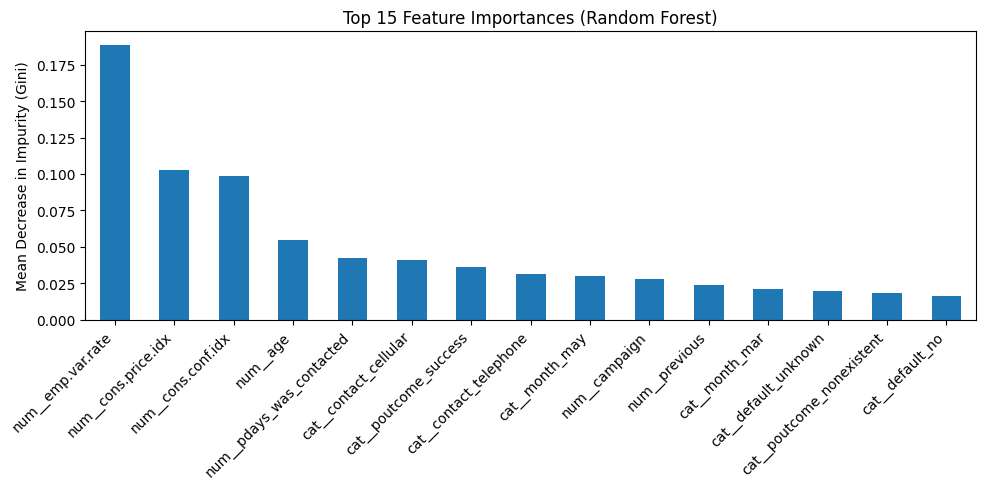

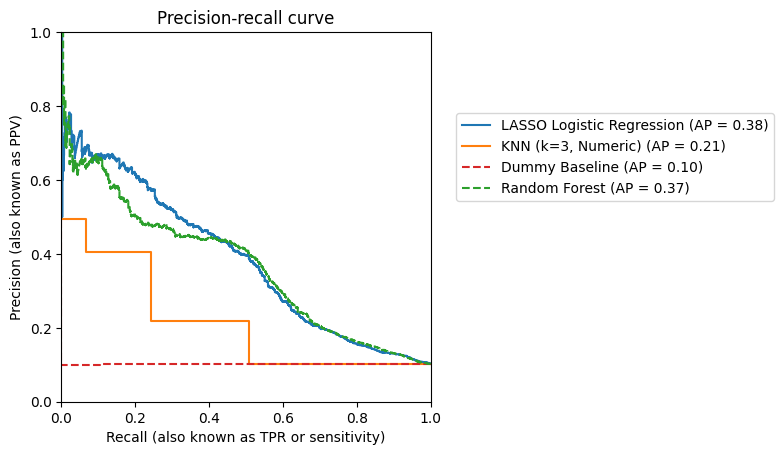

In [0]:
#Get feature importances from the "rf" step and transformed names from "preprocessor"
importances = best_rf.named_steps["rf"].feature_importances_
feature_names=best_rf.named_steps["preprocessor"].get_feature_names_out()

# Create a Series and plot the top 15 most important features
importance=pd.Series(importances, index=feature_names)

plt.figure(figsize=(10, 5))
importance.sort_values(ascending=False).head(15).plot(kind="bar")
plt.title("Top 15 Feature Importances (Random Forest)")
plt.ylabel("Mean Decrease in Impurity (Gini)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



# Precision-Recall curve comparing LASSO, KNN, and Dummy on the test set
from sklearn.metrics import PrecisionRecallDisplay

disp = PrecisionRecallDisplay.from_estimator(
    best_logreg, x_test, y_test, pos_label=1, name="LASSO Logistic Regression"
)
PrecisionRecallDisplay.from_estimator(
    best_knn, x_test, y_test, pos_label=1, name="KNN (k=3, Numeric)", ax=disp.ax_
)
PrecisionRecallDisplay.from_estimator(
    dummy,
    x_test,
    y_test,
    pos_label=1,
    name="Dummy Baseline",
    color="tab:red",
    linestyle="--",
    ax=disp.ax_,
)
PrecisionRecallDisplay.from_estimator(
    best_rf,
    x_test,
    y_test,
    pos_label=1,
    name="Random Forest",
    color="tab:green", 
    linestyle='--',
    ax=disp.ax_,
)

plt.xlabel("Recall (also known as TPR or sensitivity)")
plt.ylabel("Precision (also known as PPV)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
disp.ax_.set_title("Precision-recall curve")
plt.show()



Naive Bayes model

In [0]:
#Naive Bayes model
# Add small variance smoothing (var_smoothing=1e-2) to prevent zero-variance warnings on rare categories
# Naive Bayes applies Bayes' theorem assuming conditional independence between features
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    PrecisionRecallDisplay,
)

#Identify numerical and categorical columns from x_train
num_cols=x_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols=x_train.select_dtypes(include=["object", "category"]).columns.tolist()

#Scale numerical columns and one-hot encode categorical columns
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore",sparse_output=False), cat_cols),
    ]
)

#Create the pipeline
#we will apply Sequential Feature Elimination
from sklearn.feature_selection import SequentialFeatureSelector, VarianceThreshold

naive_bayes_sfs = Pipeline([
    ("preprocessor", preprocessor),
    ("var_thresh", VarianceThreshold(threshold=1e-4)),
    (
        "sfs",
        SequentialFeatureSelector(
            estimator=GaussianNB(var_smoothing=1e-2),
            n_features_to_select=15,
            direction="forward",
            scoring="f1",
            cv=5,
            n_jobs=-1,
        ),
    ),
    ("naive_bayes", GaussianNB(var_smoothing=1e-2)),
])

#Fit SFS + GaussianNB on the training set
naive_bayes_sfs.fit(x_train, y_train)

#Inspect which 15 encoded features were selected
all_features = naive_bayes_sfs.named_steps["preprocessor"].get_feature_names_out()
kept_after_var = all_features[naive_bayes_sfs.named_steps["var_thresh"].get_support()]
selected_features = kept_after_var[naive_bayes_sfs.named_steps["sfs"].get_support()]
print(f"Selected {len(selected_features)} features:\n", selected_features)

#Predict and evaluate Naive Bayes + SFS strictly on the unseen test set
y_pred_nb = naive_bayes_sfs.predict(x_test)

print("\n--- Test Set Results (Naive Bayes + SFS) ---")
print("Test Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Test Precision:", precision_score(y_test, y_pred_nb, zero_division=0))
print("Test Recall:", recall_score(y_test, y_pred_nb))
print("Test F1:", f1_score(y_test, y_pred_nb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))




Selected 15 features:
 ['num__age' 'num__emp.var.rate' 'num__cons.conf.idx'
 'num__pdays_was_contacted' 'cat__job_retired' 'cat__job_student'
 'cat__job_unemployed' 'cat__marital_single'
 'cat__education_university.degree' 'cat__month_apr' 'cat__month_dec'
 'cat__month_mar' 'cat__month_may' 'cat__month_oct' 'cat__month_sep']

--- Test Set Results (Naive Bayes + SFS) ---
Test Accuracy: 0.8834489848368029
Test Precision: 0.4150375939849624
Test Recall: 0.34760705289672544
Test F1: 0.37834132967786155

Confusion Matrix:
 [[6599  389]
 [ 518  276]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.94      0.94      6988
           1       0.42      0.35      0.38       794

    accuracy                           0.88      7782
   macro avg       0.67      0.65      0.66      7782
weighted avg       0.87      0.88      0.88      7782



Gradient Boosting

In [0]:
#Gradient Boosting model
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

num_cols = x_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = x_train.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ]
)

boosting = Pipeline([
    ("preprocessor", preprocessor),
    ("boosting", HistGradientBoostingClassifier(random_state=27, max_bins=100, max_iter=1000,early_stopping=True)),
])

param_distributions={
    "boosting__learning_rate":loguniform(0.01,0.2),
    "boosting__max_depth":randint(3,12),
    "boosting__max_leaf_nodes":(50,100,200,300),
    "boosting__l2_regularization":loguniform(0.01,10),
    "boosting__class_weight":[None,"balanced"]
}


search_cv=RandomizedSearchCV(
    boosting,
    param_distributions=param_distributions,
    scoring="f1",
    cv=skf,
    n_iter=25,
    random_state=0,
    n_jobs=2,
)

#Fit the models
search_cv.fit(x_train,y_train)
#Extract the best Gradient Boosting pipeline
best_boosting = search_cv.best_estimator_
print("The best parameters are:\n", search_cv.best_params_)
print("Best 10-fold CV F1 score (train set):\n", search_cv.best_score_)

#Predict and evaluate on the unseen test set
y_pred_boosting = best_boosting.predict(x_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_boosting))
print("Test Precision:", precision_score(y_test, y_pred_boosting, zero_division=0))
print("Test Recall:", recall_score(y_test, y_pred_boosting))
print("Test F1:", f1_score(y_test, y_pred_boosting))
print("\nClassification Report:\n", classification_report(y_test, y_pred_boosting))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_boosting))


The best parameters are:
 {'boosting__class_weight': 'balanced', 'boosting__l2_regularization': np.float64(0.2753794429736143), 'boosting__learning_rate': np.float64(0.032435814017449674), 'boosting__max_depth': 11, 'boosting__max_leaf_nodes': 100}
Best 10-fold CV F1 score (train set):
 0.4096022437807599
Test Accuracy: 0.8308918015934207
Test Precision: 0.31645569620253167
Test Recall: 0.5667506297229219
Test F1: 0.40613718411552346

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.86      0.90      6988
           1       0.32      0.57      0.41       794

    accuracy                           0.83      7782
   macro avg       0.63      0.71      0.65      7782
weighted avg       0.88      0.83      0.85      7782


Confusion Matrix:
 [[6016  972]
 [ 344  450]]


Learning Curve and Precision vs Recall plots

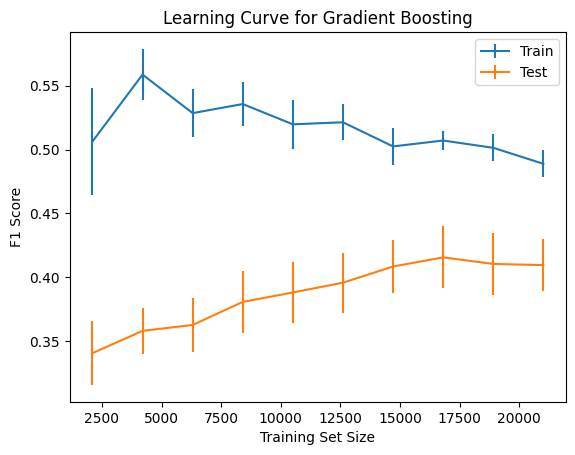

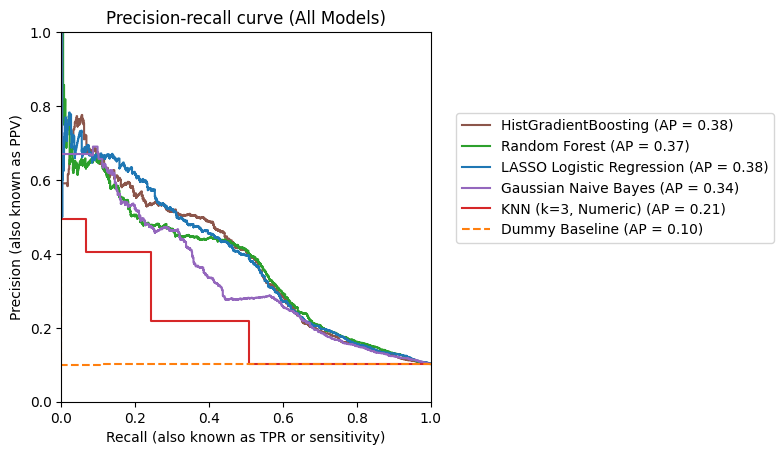

In [0]:
#learning curve for the boosting model
from sklearn.model_selection import LearningCurveDisplay

display=LearningCurveDisplay.from_estimator(
    best_boosting,
    x_train,
    y_train,
    train_sizes=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0],
    cv=skf,
    scoring="f1",
    score_type="both",
    n_jobs=2,
    random_state=0,
    line_kw={"color":"tab:orange"},
    score_name="F1",
    std_display_style="errorbar",
)
display.ax_.set(xlabel="Training Set Size", ylabel="F1 Score", title="Learning Curve for Gradient Boosting")
plt.show()


# Precision-Recall curve comparing all 6 models on the test set
disp = PrecisionRecallDisplay.from_estimator(
    best_boosting,
    x_test,
    y_test,
    pos_label=1,
    name="HistGradientBoosting",
    color="tab:brown",
)
PrecisionRecallDisplay.from_estimator(
    best_rf,
    x_test,
    y_test,
    pos_label=1,
    name="Random Forest",
    color="tab:green",
    ax=disp.ax_,
)
PrecisionRecallDisplay.from_estimator(
    best_logreg,
    x_test,
    y_test,
    pos_label=1,
    name="LASSO Logistic Regression",
    color="tab:blue",
    ax=disp.ax_,
)
PrecisionRecallDisplay.from_estimator(
    naive_bayes_sfs,
    x_test,
    y_test,
    pos_label=1,
    name="Gaussian Naive Bayes",
    color="tab:purple",
    ax=disp.ax_,
)
PrecisionRecallDisplay.from_estimator(
    best_knn,
    x_test,
    y_test,
    pos_label=1,
    name="KNN (k=3, Numeric)",
    color="tab:red",
    ax=disp.ax_,
)
PrecisionRecallDisplay.from_estimator(
    dummy,
    x_test,
    y_test,
    pos_label=1,
    name="Dummy Baseline",
    color="tab:orange",
    linestyle="--",
    ax=disp.ax_,
)

plt.xlabel("Recall (also known as TPR or sensitivity)")
plt.ylabel("Precision (also known as PPV)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
disp.ax_.set_title("Precision-recall curve (All Models)")
plt.show()

Results Data Frame for all implemented models in the test set

In [0]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

def find_best_threshold(model, X_tr, y_tr, cv):
    """Find F1-optimal cutoff on out-of-fold training probabilities (leak-free)."""
    oof_probs = cross_val_predict(
        model, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    thresholds = np.arange(0.10, 0.90, 0.01)
    f1s = [f1_score(y_tr, (oof_probs >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(f1s))
    return float(thresholds[best_idx])

models = {
    "Gradient Boosting": best_boosting,
    "Random Forest": best_rf,
    "LASSO Logistic Regression": best_logreg,
    "Gaussian Naive Bayes (SFS)": naive_bayes_sfs,
    "KNN (k=3, Numeric)": best_knn,
    "Dummy Baseline": dummy,
}

# Models that receive leak-free OOF threshold tuning
models_to_tune = {"Gradient Boosting", "Random Forest", "LASSO Logistic Regression", "KNN (k=3, Numeric)"}

rows = []
tuned_thresholds = {}

for name, model in models.items():
    y_prob = model.predict_proba(x_test)[:, 1]
    y_pred_default = model.predict(x_test)

    if name in models_to_tune:
        best_t = find_best_threshold(model, x_train, y_train, cv=skf)
        y_pred_tuned = (y_prob >= best_t).astype(int)
    else:
        best_t = 0.50
        y_pred_tuned = y_pred_default

    tuned_thresholds[name] = best_t

    rows.append({
        "Model": name,
        "Default F1 (0.50)": f1_score(y_test, y_pred_default),
        "Optimal Threshold": round(best_t, 2),
        "Test Accuracy": accuracy_score(y_test, y_pred_tuned),
        "Test Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
        "Test Recall": recall_score(y_test, y_pred_tuned),
        "Test F1 (Tuned)": f1_score(y_test, y_pred_tuned),
        "Test AP": average_precision_score(y_test, y_prob),
    })

results_df = pd.DataFrame(rows).sort_values(by="Test F1 (Tuned)", ascending=False)
print(results_df.round(4).to_string(index=False))

                     Model  Default F1 (0.50)  Optimal Threshold  Test Accuracy  Test Precision  Test Recall  Test F1 (Tuned)  Test AP
             Random Forest             0.4098               0.62         0.8741          0.4061       0.5063           0.4507   0.3667
         Gradient Boosting             0.4061               0.63         0.8723          0.4002       0.5050           0.4465   0.3776
 LASSO Logistic Regression             0.3798               0.68         0.8712          0.3964       0.5013           0.4427   0.3834
Gaussian Naive Bayes (SFS)             0.3783               0.50         0.8834          0.4150       0.3476           0.3783   0.3356
        KNN (k=3, Numeric)             0.3026               0.34         0.8863          0.4042       0.2418           0.3026   0.2121
            Dummy Baseline             0.1015               0.50         0.8111          0.0986       0.1045           0.1015   0.1017


Final Evaluation of the Winning Model on the Held-Out Validation Set

In [0]:
# Automatically select the winning model and its train-CV threshold from results_df
best_model_name = results_df.iloc[0]["Model"]
winner_model = models[best_model_name]
winner_thresh = tuned_thresholds[best_model_name]

valid_probs = winner_model.predict_proba(x_valid)[:, 1]
y_pred_valid = (valid_probs >= winner_thresh).astype(int)

print(f"\n--- Held-Out Validation Set Results: {best_model_name} (threshold = {winner_thresh:.2f}) ---")
print("Validation Accuracy:", round(accuracy_score(y_valid, y_pred_valid), 4))
print("Validation Precision:", round(precision_score(y_valid, y_pred_valid, zero_division=0), 4))
print("Validation Recall:", round(recall_score(y_valid, y_pred_valid), 4))
print("Validation F1:", round(f1_score(y_valid, y_pred_valid), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_valid, y_pred_valid))
print("\nClassification Report:\n", classification_report(y_valid, y_pred_valid))


--- Held-Out Validation Set Results: Random Forest (threshold = 0.62) ---
Validation Accuracy: 0.8756
Validation Precision: 0.411
Validation Recall: 0.5063
Validation F1: 0.4537

Confusion Matrix:
 [[6413  576]
 [ 392  402]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.92      0.93      6989
           1       0.41      0.51      0.45       794

    accuracy                           0.88      7783
   macro avg       0.68      0.71      0.69      7783
weighted avg       0.89      0.88      0.88      7783



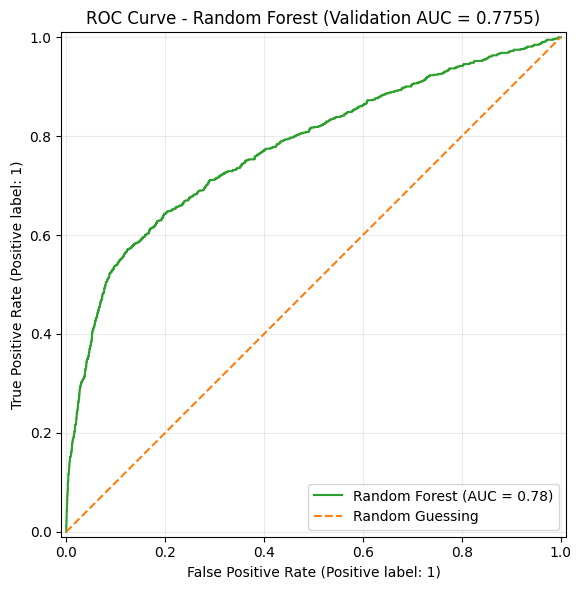

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_auc_score

fig, ax = plt.subplots(figsize=(8, 6))

roc_disp = RocCurveDisplay.from_estimator(
    winner_model,
    x_valid,
    y_valid,
    name=best_model_name,
    curve_kwargs={"color": "tab:green"},
    ax=ax,
)

y_valid_prob = winner_model.predict_proba(x_valid)[:, 1]
val_auc = roc_auc_score(y_valid, y_valid_prob)

ax.set_title(f"ROC Curve - {best_model_name} (Validation AUC = {val_auc:.4f})")
ax.plot([0, 1], [0, 1], color="tab:orange", linestyle="--", lw=1.5, label="Random Guessing")
ax.grid(alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()